In [1]:
import sys

print("Python version:")
print(sys.version)

print("\nPython executable:")
print(sys.executable)

Python version:
3.13.15 (tags/v3.13.15:4061bc4, Aug  5 2026, 13:05:39) [MSC v.1944 64 bit (AMD64)]

Python executable:
e:\RabTech_Task_4\venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np

# Load Titanic dataset
df = pd.read_csv("titanic.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Shape: (891, 12)

Columns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [1]:
# Make a copy of the dataset
data = df.copy()

# Handle missing Age values using median
data["Age"] = data["Age"].fillna(data["Age"].median())

# Handle missing Embarked values using mode
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])

# Create CabinKnown feature
# 1 = Cabin information available
# 0 = Cabin information missing
data["CabinKnown"] = data["Cabin"].notna().astype(int)

# Create FamilySize feature
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1

# Create IsAlone feature
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

# Create AgeGroup feature
data["AgeGroup"] = pd.cut(
    data["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Adult", "MiddleAge", "Senior"]
)

print("Preprocessing and feature creation completed!")

print("\nMissing values after handling:")
print(data.isnull().sum())

NameError: name 'df' is not defined

In [2]:
import pandas as pd
import numpy as np

# Load Titanic dataset
df = pd.read_csv("titanic.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (891, 12)


In [3]:
# Make a copy of the dataset
data = df.copy()

# Handle missing Age values using median
data["Age"] = data["Age"].fillna(data["Age"].median())

# Handle missing Embarked values using mode
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])

# Create CabinKnown feature
data["CabinKnown"] = data["Cabin"].notna().astype(int)

# Create FamilySize feature
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1

# Create IsAlone feature
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

# Create AgeGroup feature
data["AgeGroup"] = pd.cut(
    data["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Adult", "MiddleAge", "Senior"]
)

print("Preprocessing and feature creation completed!")

print("\nMissing values after handling:")
print(data.isnull().sum())

Preprocessing and feature creation completed!

Missing values after handling:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
CabinKnown       0
FamilySize       0
IsAlone          0
AgeGroup         0
dtype: int64


In [4]:
# Encode categorical features

data["Sex"] = data["Sex"].map({
    "male": 0,
    "female": 1
})

data["Embarked"] = data["Embarked"].map({
    "S": 0,
    "C": 1,
    "Q": 2
})

data["AgeGroup"] = data["AgeGroup"].cat.codes

print("Categorical features encoded successfully!")

print("\nEncoded features:")
display(data[["Sex", "Embarked", "AgeGroup"]].head())

Categorical features encoded successfully!

Encoded features:


,Sex,Embarked,AgeGroup
0,0,0,2
1,1,1,3
2,1,0,2
3,1,0,2
4,0,0,2


In [5]:
# Select features and target

features = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
    "Embarked", "CabinKnown", "FamilySize", "IsAlone", "AgeGroup"
]

X = data[features]
y = data["Survived"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nFeatures used:")
print(features)

print("\nTarget distribution:")
print(y.value_counts())

Features (X) shape: (891, 11)
Target (y) shape: (891,)

Features used:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'CabinKnown', 'FamilySize', 'IsAlone', 'AgeGroup']

Target distribution:
Survived
0    549
1    342
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (712, 11)
Testing data: (179, 11)
Training target: (712,)
Testing target: (179,)


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}

print("4 models created successfully!")
print("\nModels:")
for name in models:
    print("-", name)

4 models created successfully!

Models:
- Logistic Regression
- Random Forest
- Gradient Boosting
- SVM


In [8]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

# Stratified K-Fold Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified K-Fold Cross-Validation created successfully!")
print("Number of folds:", cv.n_splits)

Stratified K-Fold Cross-Validation created successfully!
Number of folds: 5


In [9]:
# Hyperparameter tuning for Logistic Regression

param_grid_lr = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"]
}

grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid_lr,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

print("Logistic Regression tuning completed!")
print("Best parameters:", grid_lr.best_params_)
print("Best CV F1-score:", round(grid_lr.best_score_, 4))

Logistic Regression tuning completed!
Best parameters: {'C': 1, 'solver': 'lbfgs'}
Best CV F1-score: 0.7436


In [10]:
# Hyperparameter tuning for Random Forest

param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Random Forest tuning completed!")
print("Best parameters:", grid_rf.best_params_)
print("Best CV F1-score:", round(grid_rf.best_score_, 4))

Random Forest tuning completed!
Best parameters: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
Best CV F1-score: 0.7726


In [11]:
# Hyperparameter tuning for Gradient Boosting

param_grid_gb = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3]
}

grid_gb = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid_gb,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_gb.fit(X_train, y_train)

print("Gradient Boosting tuning completed!")
print("Best parameters:", grid_gb.best_params_)
print("Best CV F1-score:", round(grid_gb.best_score_, 4))

Gradient Boosting tuning completed!
Best parameters: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}
Best CV F1-score: 0.7728


In [12]:
# Hyperparameter tuning for SVM

param_grid_svm = {
    "C": [0.1, 1, 10, 100],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", "auto"]
}

grid_svm = GridSearchCV(
    SVC(probability=True, random_state=42),
    param_grid_svm,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_svm.fit(X_train, y_train)

print("SVM tuning completed!")
print("Best parameters:", grid_svm.best_params_)
print("Best CV F1-score:", round(grid_svm.best_score_, 4))

SVM tuning completed!
Best parameters: {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV F1-score: 0.7287


e:\RabTech_Task_4\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [13]:
# Store the best tuned models

best_models = {
    "Logistic Regression": grid_lr.best_estimator_,
    "Random Forest": grid_rf.best_estimator_,
    "Gradient Boosting": grid_gb.best_estimator_,
    "SVM": grid_svm.best_estimator_
}

print("All 4 tuned models stored successfully!")

All 4 tuned models stored successfully!


In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

results = []

for name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print("Model evaluation completed!")
display(results_df.round(4))

Model evaluation completed!


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8156,0.7727,0.7391,0.7556,0.8513
1,Random Forest,0.7989,0.7538,0.7101,0.7313,0.8439
2,Gradient Boosting,0.7989,0.7895,0.6522,0.7143,0.7992
3,SVM,0.7989,0.7538,0.7101,0.7313,0.8283


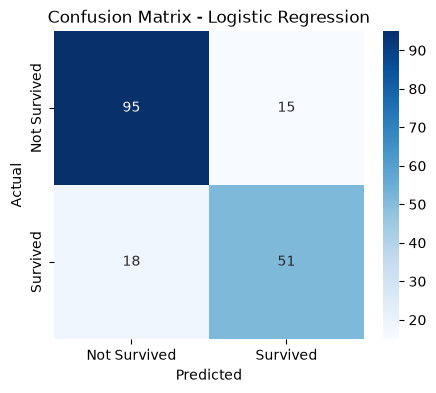

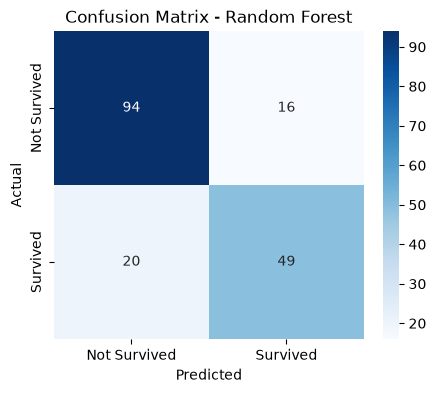

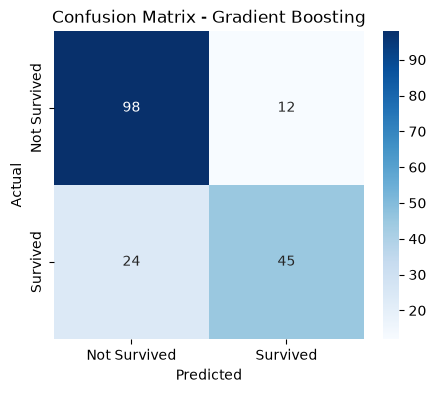

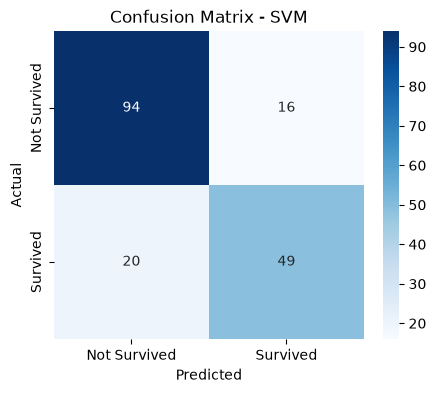

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

for name, model in best_models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Survived", "Survived"],
        yticklabels=["Not Survived", "Survived"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

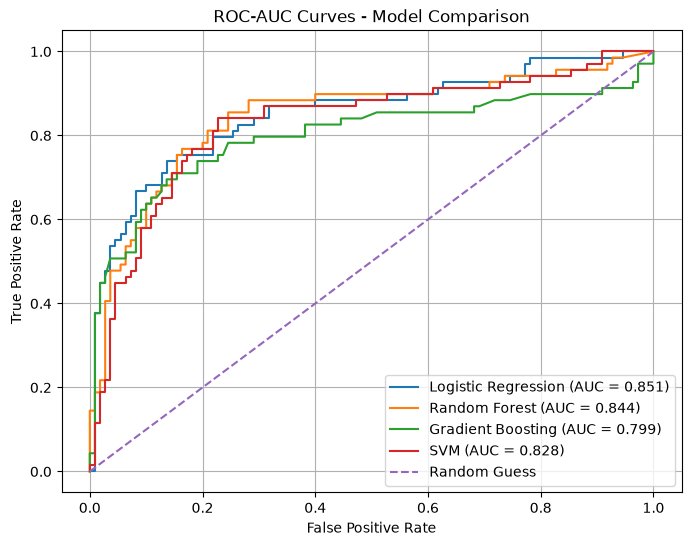

In [16]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, model in best_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.title("ROC-AUC Curves - Model Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

In [17]:
import pickle

# Select Champion Model
champion_model = best_models["Logistic Regression"]

# Save Champion Model
with open("champion_model.pkl", "wb") as file:
    pickle.dump(champion_model, file)

# Save model comparison table
results_df.to_csv("model_comparison.csv", index=False)

print("Champion model saved successfully!")
print("File: champion_model.pkl")

print("\nModel comparison table saved successfully!")
print("File: model_comparison.csv")

Champion model saved successfully!
File: champion_model.pkl

Model comparison table saved successfully!
File: model_comparison.csv


In [18]:
import pickle

# Load saved champion model
with open("champion_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

# Test prediction
sample_prediction = loaded_model.predict(X_test)

print("Champion model loaded successfully!")
print("Model type:", type(loaded_model).__name__)
print("Test predictions generated:", len(sample_prediction))

Champion model loaded successfully!
Model type: LogisticRegression
Test predictions generated: 179
